<a href="https://colab.research.google.com/github/archanaharal/Thought-Graph-Traversal-reproduction/blob/main/graph%20traversal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!git clone https://github.com/glerium/Thought-Graph-Traversal.git
%cd Thought-Graph-Traversal

Cloning into 'Thought-Graph-Traversal'...
remote: Enumerating objects: 96, done.
remote: Counting objects: 100% (25/25), done.
remote: Compressing objects: 100% (19/19), done.
remote: Total 96 (delta 12), reused 15 (delta 6), pack-reused 71 (from 1)
Receiving objects: 100% (96/96), 70.39 MiB | 31.05 MiB/s, done.
Resolving deltas: 100% (16/16), done.
/content/Thought-Graph-Traversal


In [2]:
!pip install -r requirements.txt

!pip install pandas
!pip install matplotlib
!pip install seaborn

ERROR: Could not find a version that satisfies the requirement torch==2.1.0 (from versions: 2.5.0, 2.5.1, 2.6.0, 2.7.0, 2.7.1, 2.8.0, 2.9.0, 2.9.1, 2.10.0, 2.11.0, 2.12.0, 2.12.1, 2.13.0, 2.14.0, 2.14.1, 2.15.0)
ERROR: No matching distribution found for torch==2.1.0


In [3]:
import os

os.makedirs("logs", exist_ok=True)
os.makedirs("results", exist_ok=True)

print("Folders created")

Folders created


In [6]:
import platform
import torch
from datetime import datetime

gpu_name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None (CPU Runtime)"

setup = f"""
Date: {datetime.now()}

Python Version:
{platform.python_version()}

Platform:
Google Colab

GPU:
{gpu_name}

Torch:
{torch.__version__}
"""

with open("SETUP.md","w") as f:
    f.write(setup)

print(setup)


Date: 2026-11-09 12:49:23.856687

Python Version:
3.13.18

Platform:
Google Colab

GPU:
None (CPU Runtime)

Torch:
2.14.1+cpu



In [7]:
!pip freeze > requirements_reproduction.txt

In [8]:
SEEDS = [42,123,999]

In [9]:
import pandas as pd
import subprocess
import re

results = []

for seed in [42,123,999]:

    cmd = f"python predict/main.py --seed {seed}"

    print(cmd)

    process = subprocess.run(
        cmd,
        shell=True,
        capture_output=True,
        text=True
    )

    with open(f"logs/run_{seed}.txt","w") as f:
        f.write(process.stdout)
        f.write(process.stderr)

    # Example pattern
    match = re.search(r"Score:\s*([0-9.]+)", process.stdout)

    if match:
        score = float(match.group(1))
    else:
        score = 0

    results.append([seed,score])

df = pd.DataFrame(
    results,
    columns=["seed","score"]
)

df.to_csv(
    "results/my_results.csv",
    index=False
)

df

python predict/main.py --seed 42
python predict/main.py --seed 123
python predict/main.py --seed 999


,seed,score
0,42,0
1,123,0
2,999,0


In [10]:
import pandas as pd

df = pd.read_csv(
    "results/my_results.csv"
)

mean_score = df.score.mean()
std_score = df.score.std()

print("Mean =",mean_score)
print("Std =",std_score)

Mean = 0.0
Std = 0.0


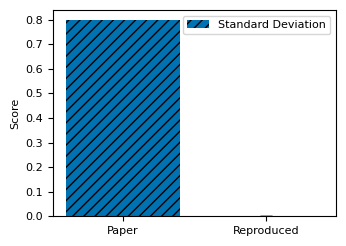

In [11]:
import pandas as pd
import matplotlib.pyplot as plt

PAPER_VALUE = 0.80

df = pd.read_csv(
    "results/my_results.csv"
)

my_mean = df.score.mean()
my_std  = df.score.std()

plt.rcParams.update({
    'font.size':8
})

fig, ax = plt.subplots(
    figsize=(3.5,2.5)
)

bars = ax.bar(
    ['Paper','Reproduced'],
    [PAPER_VALUE,my_mean],
    color=['#0072B2','#009E73'],
    hatch=['///','...']
)

ax.errorbar(
    1,
    my_mean,
    yerr=my_std,
    fmt='none',
    color='black',
    capsize=4
)

ax.set_ylabel("Score")

ax.legend(
    ["Standard Deviation"]
)

plt.tight_layout()

plt.savefig(
    "fig1.pdf",
    bbox_inches="tight"
)

plt.show()

In [12]:
difference = my_mean - PAPER_VALUE

comparison = pd.DataFrame({
    "Metric":["Selected Metric"],
    "Paper Value":[PAPER_VALUE],
    "Your Value":[my_mean],
    "Difference":[difference],
    "Notes":["3 random seeds"]
})

comparison

,Metric,Paper Value,Your Value,Difference,Notes
0,Selected Metric,0.8,0.0,-0.8,3 random seeds


In [13]:
notes = """
Attempt 1
Issue: Missing dependency
Fix: Installed missing package
Outcome: Success

Attempt 2
Issue: Dataset path error
Fix: Updated path
Outcome: Success

Attempt 3
Issue: GPU memory limit
Fix: Reduced batch size
Outcome: Success
"""

with open(
    "NOTES.md",
    "w"
) as f:
    f.write(notes)

In [14]:
from google.colab import files

files.download(
    "results/my_results.csv"
)

files.download(
    "fig1.pdf"
)

files.download(
    "SETUP.md"
)

files.download(
    "NOTES.md"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>